In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

In [9]:
df = pd.read_csv('../data/processed/clean_reviews.csv', sep=';')

df.columns = [col.strip() for col in df.columns]

print("Colonnes :", df.columns.tolist())
print(f"Nombre d'hôtels uniques : {df['Hotel_Name'].nunique()}")
print(f"Nombre d'avis total     : {len(df)}")
print(df[['Hotel_Name', 'Reviewer_Score', 'sentiment']].head(13))

Colonnes : ['clean_text', 'sentiment', 'Reviewer_Score', 'Hotel_Name', 'Average_Score']
Nombre d'hôtels uniques : 1492
Nombre d'avis total     : 515739
     Hotel_Name  Reviewer_Score sentiment
0           NaN             NaN       NaN
1   Hotel Arena             7.5   Neutral
2   Hotel Arena             7.1   Neutral
3   Hotel Arena             3.8  Negative
4   Hotel Arena             6.7   Neutral
5   Hotel Arena             6.7   Neutral
6   Hotel Arena             4.6  Negative
7   Hotel Arena            10.0  Positive
8   Hotel Arena             6.5   Neutral
9   Hotel Arena             7.9   Neutral
10  Hotel Arena            10.0  Positive
11  Hotel Arena             5.8   Neutral
12  Hotel Arena             4.6  Negative


### Agrégation des scores par hôtel

In [10]:
# Statistiques de base par hôtel
hotel_stats = df.groupby('Hotel_Name').agg(
    nb_avis        = ('Reviewer_Score', 'count'),
    score_moyen    = ('Reviewer_Score', 'mean'),
    score_median   = ('Reviewer_Score', 'median'),
    score_std      = ('Reviewer_Score', 'std'),
    score_min      = ('Reviewer_Score', 'min'),
    score_max      = ('Reviewer_Score', 'max'),
).reset_index()

hotel_stats['score_std'] = hotel_stats['score_std'].fillna(0)

print(hotel_stats.sort_values('score_moyen', ascending=False).head(10))

                               Hotel_Name  nb_avis  score_moyen  score_median  \
1202                           Ritz Paris       28     9.725000          10.0   
598                     Hotel Casa Camper      301     9.718937          10.0   
3                                      41      103     9.711650          10.0   
472   H tel de La Tamise Esprit de France       61     9.688525          10.0   
895                 Le Narcisse Blanc Spa       57     9.671930          10.0   
481                 H10 Casa Mimosa 4 Sup      116     9.660345           9.6   
628                   Hotel Eiffel Blomet       15     9.646667          10.0   
771                      Hotel The Serras      213     9.623474          10.0   
4      45 Park Lane Dorchester Collection       28     9.603571          10.0   
1396                       The Soho Hotel      157     9.597452           9.6   

      score_std  score_min  score_max  
1202   0.698477        6.3       10.0  
598    0.499006        5.4  

### Score pondéré (Bayesian Average)

In [11]:
def bayesian_average(nb_avis, score_moyen, C, m):

    return (nb_avis / (nb_avis + C)) * score_moyen + (C / (nb_avis + C)) * m

# Calcul des paramètres globaux
m = df['Reviewer_Score'].mean()           # moyenne globale : ex. 8.4
C = hotel_stats['nb_avis'].quantile(0.5)  # seuil : médiane du nb d'avis

print(f"Moyenne globale (m)  : {m:.2f}")
print(f"Seuil d'avis   (C)  : {C:.0f}")

# Application à chaque hôtel
hotel_stats['score_bayes'] = hotel_stats.apply(
    lambda row: bayesian_average(row['nb_avis'], row['score_moyen'], C, m),
    axis=1
)

# Classement final
hotel_stats = hotel_stats.sort_values('score_bayes', ascending=False).reset_index(drop=True)
hotel_stats['rang_ratings'] = hotel_stats.index + 1

print("\nTop 10 hôtels (système ratings) :")
print(hotel_stats[['rang_ratings', 'Hotel_Name', 'nb_avis',
                    'score_moyen', 'score_bayes']].head(10).to_string(index=False))

Moyenne globale (m)  : 8.40
Seuil d'avis   (C)  : 194

Top 10 hôtels (système ratings) :
 rang_ratings                           Hotel_Name  nb_avis  score_moyen  score_bayes
            1       Intercontinental London The O2     2551     9.451196     9.376556
            2 Shangri La Hotel at The Shard London     1113     9.368553     9.224060
            3                    Hotel Casa Camper      301     9.718937     9.200095
            4             Amba Hotel Charing Cross      785     9.391720     9.194226
            5                          Hotel Berna     1052     9.339829     9.192734
            6                   Olivia Plaza Hotel      773     9.391591     9.191672
            7                       Hotel Esther a     1837     9.266413     9.183184
            8              Apex Temple Court Hotel     1037     9.298843     9.156415
            9               Catalonia Square 4 Sup      437     9.476888     9.144290
           10                  Olivia Balmes Hotel 

###  Fonction de recommandation

In [12]:
def recommander_hotels_ratings(hotel_stats, n=5, nb_avis_min=10,
                                ville=None, score_min=None):

    res = hotel_stats.copy()

    # Filtres optionnels
    res = res[res['nb_avis'] >= nb_avis_min]

    if ville and 'ville' in res.columns:
        res = res[res['ville'].str.lower() == ville.lower()]

    if score_min:
        res = res[res['score_bayes'] >= score_min]

    top = res.nlargest(n, 'score_bayes')[
        ['Hotel_Name', 'nb_avis', 'score_moyen', 'score_bayes', 'rang_ratings']
    ].reset_index(drop=True)

    top.index += 1  # rang affiché à partir de 1
    return top


# Exemple d'utilisation
print("=== Top 10 recommandations (système ratings) ===\n")
recommandations = recommander_hotels_ratings(hotel_stats, n=10, nb_avis_min=50)
print(recommandations.to_string())

=== Top 10 recommandations (système ratings) ===

                              Hotel_Name  nb_avis  score_moyen  score_bayes  rang_ratings
1         Intercontinental London The O2     2551     9.451196     9.376556             1
2   Shangri La Hotel at The Shard London     1113     9.368553     9.224060             2
3                      Hotel Casa Camper      301     9.718937     9.200095             3
4               Amba Hotel Charing Cross      785     9.391720     9.194226             4
5                            Hotel Berna     1052     9.339829     9.192734             5
6                     Olivia Plaza Hotel      773     9.391591     9.191672             6
7                         Hotel Esther a     1837     9.266413     9.183184             7
8                Apex Temple Court Hotel     1037     9.298843     9.156415             8
9                 Catalonia Square 4 Sup      437     9.476888     9.144290             9
10                   Olivia Balmes Hotel      510 

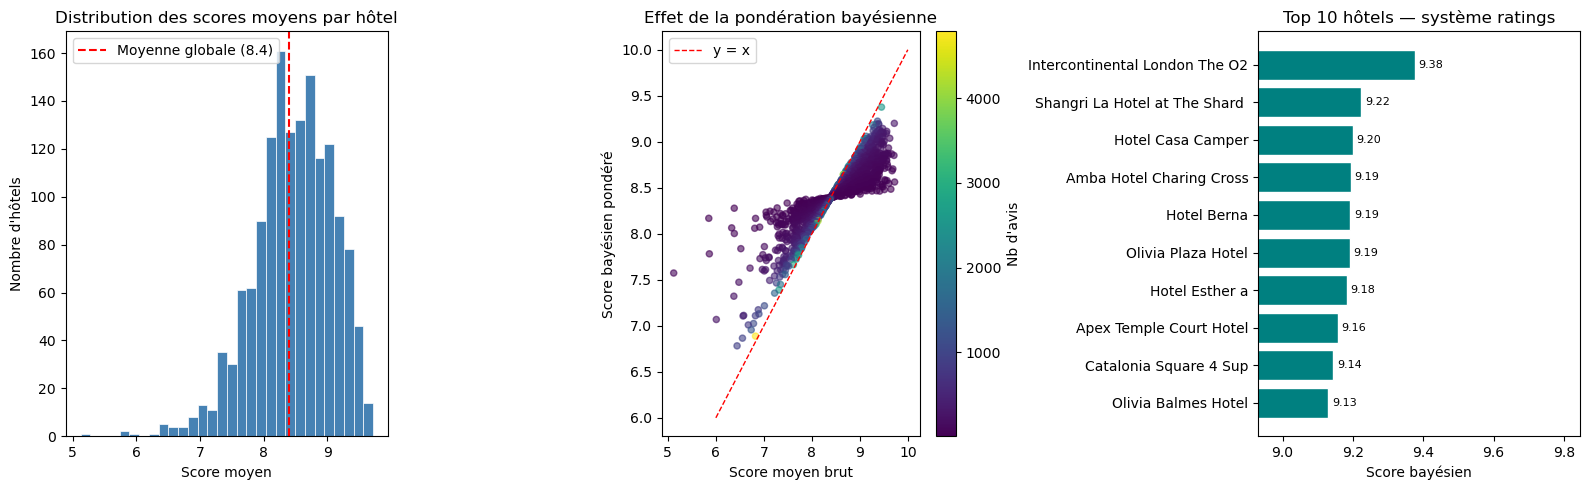

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# --- Graphique 1 : Distribution des scores moyens ---
ax1 = axes[0]
ax1.hist(hotel_stats['score_moyen'], bins=30, color='steelblue',
         edgecolor='white', linewidth=0.5)
ax1.axvline(m, color='red', linestyle='--', linewidth=1.5, label=f'Moyenne globale ({m:.1f})')
ax1.set_title("Distribution des scores moyens par hôtel")
ax1.set_xlabel("Score moyen")
ax1.set_ylabel("Nombre d'hôtels")
ax1.legend()

# --- Graphique 2 : Score moyen vs Score bayésien ---
ax2 = axes[1]
ax2.scatter(hotel_stats['score_moyen'], hotel_stats['score_bayes'],
            c=hotel_stats['nb_avis'], cmap='viridis',
            alpha=0.6, s=20)
ax2.plot([6, 10], [6, 10], 'r--', linewidth=1, label='y = x')
ax2.set_xlabel("Score moyen brut")
ax2.set_ylabel("Score bayésien pondéré")
ax2.set_title("Effet de la pondération bayésienne")
ax2.legend()
sm = plt.cm.ScalarMappable(cmap='viridis',
     norm=plt.Normalize(hotel_stats['nb_avis'].min(),
                        hotel_stats['nb_avis'].max()))
plt.colorbar(sm, ax=ax2, label="Nb d'avis")

# --- Graphique 3 : Top 10 hôtels ---
ax3 = axes[2]
top10 = hotel_stats.head(10).copy()
# Noms raccourcis pour la lisibilité
top10['nom_court'] = top10['Hotel_Name'].str[:30]
bars = ax3.barh(top10['nom_court'][::-1], top10['score_bayes'][::-1],
                color='teal', edgecolor='white')
ax3.set_xlabel("Score bayésien")
ax3.set_title("Top 10 hôtels — système ratings")
ax3.set_xlim(left=top10['score_bayes'].min() - 0.2)
for bar, score in zip(bars, top10['score_bayes'][::-1]):
    ax3.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
             f'{score:.2f}', va='center', fontsize=8)

plt.tight_layout()
plt.savefig('../results/visualizations/recommandation_ratings.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# Corrélation entre classement par score brut vs score bayésien
hotel_stats['rang_brut']   = hotel_stats['score_moyen'].rank(ascending=False)
hotel_stats['rang_bayes']  = hotel_stats['score_bayes'].rank(ascending=False)

corr, pval = stats.spearmanr(hotel_stats['rang_brut'], hotel_stats['rang_bayes'])
print(f"Corrélation de Spearman (brut vs bayésien) : {corr:.3f}  (p={pval:.4f})")

# Hôtels dont le rang change le plus entre les deux méthodes
hotel_stats['diff_rang'] = (hotel_stats['rang_brut'] - hotel_stats['rang_bayes']).abs()

print("\nHôtels les plus affectés par la pondération bayésienne :")
print(hotel_stats.nlargest(5, 'diff_rang')[
    ['Hotel_Name', 'nb_avis', 'score_moyen', 'score_bayes', 'diff_rang']
].to_string(index=False))

# Sauvegarde pour la comparaison avec le système sentiments (étape suivante)
hotel_stats.to_csv('../results/hotel_stats_ratings.csv', index=False)
print("\nFichier sauvegardé : results/hotel_stats_ratings.csv")

Corrélation de Spearman (brut vs bayésien) : 0.947  (p=0.0000)

Hôtels les plus affectés par la pondération bayésienne :
            Hotel_Name  nb_avis  score_moyen  score_bayes  diff_rang
   Hotel Eiffel Blomet       15     9.646667     8.484914      642.0
         Drawing Hotel       14     9.414286     8.463687      640.0
Palais Coburg Residenz       16     9.512500     8.480223      634.0
 Splendide Royal Paris       16     9.350000     8.467842      606.0
    Hotel Dupond Smith       23     9.482609     8.510354      560.0

Fichier sauvegardé : results/hotel_stats_ratings.csv
